<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Feed Parser](https://github.com/Query-farm/vgi-feed)

Fetch feeds into SQL rows and import or generate feed documents with COPY.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-feed/blob/main/notebooks/02_export_order_is_not_identity.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-feed/blob/main/notebooks/README.md)


## 02 · Export order is not item identity

A feed round trip can preserve every item while changing its position and filling
a field that was absent in the source. We will import the authored RSS bulletin,
export the same ten rows to RSS, Atom and JSON Feed, then re-import each document.
SQL will reconcile stable IDs and common fields separately from source positions
and update timestamps.

All documents are synthetic. COPY writes only into this example's local
`artifacts/roundtrip` directory; no feed is published and no external URL is fetched.

### Choose the order of the exported rows

`EXPORT_ORDER` accepts **"source"** or **"published_desc"**. The default retains
the original nonchronological ordering. The experiment sorts newest publication
first, breaking ties by GUID. Every item remains included; this changes order,
not a retrieval cap or an item identity.

In [1]:
EXPORT_ORDER = "source"  # Experiment: "published_desc"

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.23":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.23"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from pathlib import Path
from IPython.display import display
from vgi_notebooks import check_runtime, connect, prepare, prose, theme

check_runtime()
prepare("feed")
import feed_example as example  # noqa: E402 — download before import

example.validate_order(EXPORT_ORDER)
Path("artifacts/roundtrip").mkdir(parents=True, exist_ok=True)
theme()
session = connect(globals())
connection = session.connection
connection.execute("SET TimeZone='UTC'")

### Connect to the release and inspect its COPY formats

Public release **v0.5.0** provides the prebuilt worker. Its COPY registry ties each
format to a direction and handler: `feed.auto` imports, while `feed.rss`,
`feed.atom` and `feed.jsonfeed` export. `ordered=true` on the writers means that
query order matters. Worker-local paths refer to this notebook's working directory
because the release runs as a local subprocess.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'feed' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-feed@v0.5.0');
SELECT DISTINCT format_name,direction,ordered,handler
FROM vgi_copy_formats() WHERE catalog_name='feed' ORDER BY format_name;

,format_name,direction,ordered,handler
0,feed.atom,to,True,write_atom_copy
1,feed.auto,from,False,read_feed_copy
2,feed.jsonfeed,to,True,write_jsonfeed_copy
3,feed.rss,to,True,write_rss_copy


### Import a typed source table

A null input gives the item reader's empty schema; COPY fills that table from the
local RSS document. Column names and Arrow types determine the import mapping.
The ten authored GUIDs are absolute URNs, so all three formats can retain them.
Publication dates are known UTC instants. Source `updated` values are absent,
which will give us a useful check on export defaults.

In [5]:
%%sql original <<
CREATE TABLE source_items AS SELECT * FROM feed.main.feed_items(NULL);
COPY source_items FROM 'fixtures/feed.rss' (FORMAT 'feed.auto');
SELECT seq+1 AS source_position,guid,title,published,updated,list_sort(categories) AS categories
FROM source_items ORDER BY seq;

In [6]:
display(original)
assert connection.execute("SELECT count(*)=10 AND count(DISTINCT guid)=10 AND bool_and(starts_with(guid,'urn:bulletin:')) FROM source_items").fetchone()[0]
assert connection.execute("SELECT count(published)=10 AND count(updated)=0 FROM source_items").fetchone()[0]
prose("The source contains **ten distinct absolute IDs, ten known publication times and no update times**. We will compare those properties after export rather than treating a successful COPY row count as proof of a lossless conversion.")

,source_position,guid,title,published,updated,categories
0,1,urn:bulletin:01,Queue latency fixed,2026-01-15 11:00:00,NaT,"[operations, release]"
1,2,urn:bulletin:02,Older maintenance notice,2026-01-12 04:00:00,NaT,[operations]
2,3,urn:bulletin:03,Dataset index released,2026-01-15 00:00:00,NaT,"[data, release]"
3,4,urn:bulletin:04,Clock boundary bulletin,2026-01-15 12:00:00,NaT,[operations]
4,5,urn:bulletin:05,Schema guide revised,2026-01-14 12:00:00,NaT,"[data, release]"
5,6,urn:bulletin:06,Older data backfill,2026-01-13 00:00:00,NaT,[data]
6,7,urn:bulletin:07,Gateway patch available,2026-01-14 00:00:00,NaT,"[operations, release]"
7,8,urn:bulletin:08,Export notes clarified,2026-01-15 10:00:00,NaT,"[data, release]"
8,9,urn:bulletin:09,Future-dated preview,2026-01-15 16:00:00,NaT,[data]
9,10,urn:bulletin:10,Client patch documented,2026-01-13 13:00:00,NaT,"[operations, release]"


The source contains **ten distinct absolute IDs, ten known publication times and no update times**. We will compare those properties after export rather than treating a successful COPY row count as proof of a lossless conversion.

### Make export order explicit, then write all three formats

We materialize the chosen ordering once. `export_position` is a SQL audit column;
the COPY queries omit it because the writer accepts only item-schema fields.
Each writer receives all ten rows ordered by that audit position. The source
`seq` value is not serialized as a permanent identity: readers assign a fresh
zero-based sequence from the new document order.

These paths are owned example outputs and are replaced on rerun. RSS additionally
requires a feed description; all three writers require a title and absolute
home-page link. The authored `example.invalid` link is metadata only.

In [7]:
%%sql export_order <<
CREATE TABLE export_rows AS
SELECT row_number() OVER (ORDER BY
 CASE WHEN '{{EXPORT_ORDER}}'='source' THEN seq END ASC,
 CASE WHEN '{{EXPORT_ORDER}}'='published_desc' THEN published END DESC,guid)-1 AS export_position,*
FROM source_items;
SELECT guid,seq+1 AS source_position,export_position+1 AS export_position
FROM export_rows ORDER BY export_position;

In [8]:
%%sql
COPY (SELECT * EXCLUDE(export_position) FROM export_rows ORDER BY export_position)
TO 'artifacts/roundtrip/bulletin.rss'
(FORMAT 'feed.rss',title 'Synthetic round trip',link 'https://example.invalid/',description 'Ten authored bulletin items');

,Count


In [9]:
%%sql
COPY (SELECT * EXCLUDE(export_position) FROM export_rows ORDER BY export_position)
TO 'artifacts/roundtrip/bulletin.atom'
(FORMAT 'feed.atom',title 'Synthetic round trip',link 'https://example.invalid/');

,Count


In [10]:
%%sql
COPY (SELECT * EXCLUDE(export_position) FROM export_rows ORDER BY export_position)
TO 'artifacts/roundtrip/bulletin.json'
(FORMAT 'feed.jsonfeed',title 'Synthetic round trip',link 'https://example.invalid/');

,Count


### Re-import each output and reconcile by stable ID

Auto-detection selects the parser from the document contents. We keep the three
imports in separate tables, then attach a format label for comparison. A full
join by GUID catches both missing and unexpected IDs; checks also reject duplicate
IDs. Common-field equality compares title, link, publication instant and sorted
category labels, preserving each item independently of its position.

In [11]:
%%sql
CREATE TABLE rss_back AS SELECT * FROM source_items WHERE false;
CREATE TABLE atom_back AS SELECT * FROM source_items WHERE false;
CREATE TABLE json_back AS SELECT * FROM source_items WHERE false;
COPY rss_back FROM 'artifacts/roundtrip/bulletin.rss' (FORMAT 'feed.auto');
COPY atom_back FROM 'artifacts/roundtrip/bulletin.atom' (FORMAT 'feed.auto');
COPY json_back FROM 'artifacts/roundtrip/bulletin.json' (FORMAT 'feed.auto');
CREATE TABLE roundtrip AS
SELECT 'RSS' AS format,* FROM rss_back
UNION ALL SELECT 'Atom',* FROM atom_back
UNION ALL SELECT 'JSON',* FROM json_back;

,Count


In [12]:
%%sql reconciliation <<
CREATE TABLE roundtrip_checks AS
WITH expected AS (
 SELECT f.format,e.* FROM (VALUES ('RSS'),('Atom'),('JSON')) f(format) CROSS JOIN export_rows e
)
SELECT coalesce(e.format,b.format) AS format,coalesce(e.guid,b.guid) AS guid,
 e.guid IS NOT NULL AS expected_id,b.guid IS NOT NULL AS returned_id,
 e.seq AS original_seq,e.export_position,b.seq AS returned_seq,
 e.title IS NOT DISTINCT FROM b.title AND e.link IS NOT DISTINCT FROM b.link
 AND e.published IS NOT DISTINCT FROM b.published
 AND list_sort(e.categories) IS NOT DISTINCT FROM list_sort(b.categories) AS common_fields_equal
FROM expected e FULL OUTER JOIN roundtrip b ON e.format=b.format AND e.guid=b.guid;
SELECT format,count(*) AS identities,count(*) FILTER(WHERE expected_id AND returned_id) AS paired_ids,
 count(*) FILTER(WHERE common_fields_equal) AS common_fields_retained,
 count(*) FILTER(WHERE returned_seq=export_position) AS order_matches,
 count(*) FILTER(WHERE returned_seq<>original_seq) AS positions_changed
FROM roundtrip_checks GROUP BY format ORDER BY format;

,format,identities,paired_ids,common_fields_retained,order_matches,positions_changed
0,Atom,10,10,10,10,0
1,JSON,10,10,10,10,0
2,RSS,10,10,10,10,0


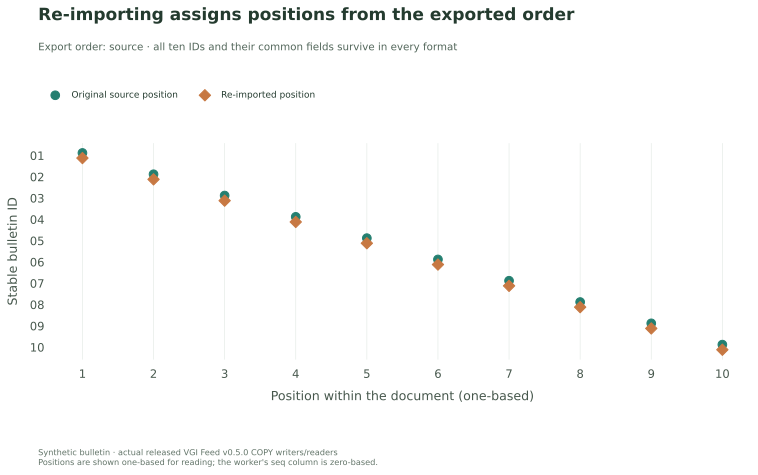

All three formats retain **10 of 10 IDs and common-field rows**, and every returned position matches the chosen export order. **0 positions differ from the original document**. A position change is not an item loss; the stable GUID is the join key.

In [13]:
display(reconciliation)
assert len(reconciliation)==3
assert (reconciliation.identities==10).all() and (reconciliation.paired_ids==10).all()
assert (reconciliation.common_fields_retained==10).all() and (reconciliation.order_matches==10).all()
assert connection.execute("SELECT count(*)=0 FROM (SELECT format,guid FROM roundtrip GROUP BY ALL HAVING count(*)<>1)").fetchone()[0]
positions=connection.execute("SELECT guid,original_seq+1 AS source_position,returned_seq+1 AS export_position FROM roundtrip_checks WHERE format='RSS' ORDER BY original_seq").df()
assert len(positions)==10
example.plot_roundtrip(positions, EXPORT_ORDER)
changed=int(reconciliation.positions_changed.iloc[0])
assert (reconciliation.positions_changed==changed).all()
prose(f"All three formats retain **10 of 10 IDs and common-field rows**, and every returned position matches the chosen export order. **{changed} positions differ from the original document**. A position change is not an item loss; the stable GUID is the join key.")

### Distinguish a defaulted timestamp from a source observation

The common-field contract deliberately excludes `updated`. Atom requires an
updated timestamp, and this writer uses the known publication time when the
input update time is missing. RSS and JSON retain the absence in this example.
A populated Atom field therefore does not establish that the publisher later
changed the item. We show the fallback and verify it against `published`.

In [14]:
%%sql updated_population <<
CREATE TABLE date_population AS
SELECT 'Source' AS format,count(*) AS items,count(updated) AS updated_present FROM source_items
UNION ALL
SELECT format,count(*),count(updated) FROM roundtrip GROUP BY format;
SELECT * FROM date_population ORDER BY CASE format WHEN 'Source' THEN 0 WHEN 'RSS' THEN 1 WHEN 'Atom' THEN 2 ELSE 3 END;

,format,items,updated_present
0,Source,10,0
1,RSS,10,0
2,Atom,10,10
3,JSON,10,0


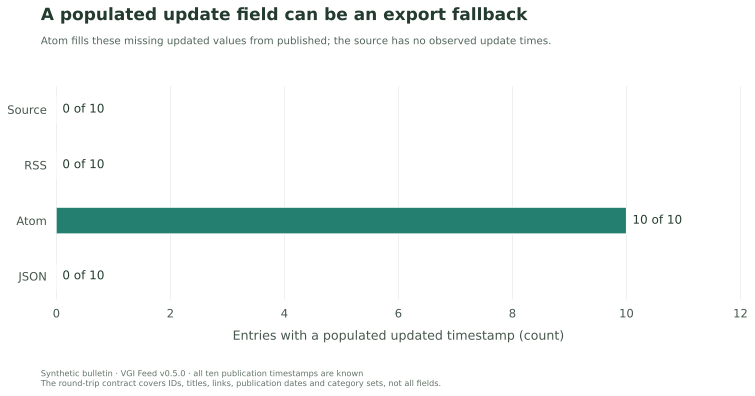

Atom returns **ten populated update times**, each equal to its known publication time. The source, RSS and JSON imports have **zero**. The conversion preserves the stated common-field contract but is not lossless equality of every field.

In [15]:
display(updated_population)
assert connection.execute("SELECT count(*)=10 AND bool_and(updated=published) FROM atom_back").fetchone()[0]
assert connection.execute("SELECT count(updated)=0 FROM rss_back").fetchone()[0]
assert connection.execute("SELECT count(updated)=0 FROM json_back").fetchone()[0]
example.plot_updated(updated_population)
prose("Atom returns **ten populated update times**, each equal to its known publication time. The source, RSS and JSON imports have **zero**. The conversion preserves the stated common-field contract but is not lossless equality of every field.")

### Experiment: sort newest first without changing the population

Change only `EXPORT_ORDER` to **"published_desc"** in a separate run. Predict
unchanged IDs, common fields and timestamp-fallback counts, but a different
mapping from each stable ID to its sequence position. Every format should obey
the same requested order. Restore **"source"** for the default.

```sh
uv run --locked vgi-notebooks 02_export_order_is_not_identity.ipynb \
  --parameters '{"EXPORT_ORDER":"published_desc"}' --output-dir artifacts/newest-first
```

Only the authored common fields are reconciled. Opaque or missing IDs, absent
publication times and format-specific content need their own conversion policy;
this example does not claim complete feed-standard validation or byte-for-byte
round trips. [The retrieval-cap notebook](01_measure_feed_prefix_coverage.ipynb)
shows why changing source order can also change which recent items a prefix contains.

In [16]:
session.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-feed](https://github.com/Query-farm/vgi-feed)